In [1]:
import pandas as pd
import pandas as numpy
import matplotlib.pyplot as plt
df=pd.read_csv("/Users/bhavya/Desktop/production_analysis.csv")

In [2]:
df.head()

,record_id,production_datetime,machine,shift,planned_hours,downtime_hours,operating_hours,production_target,actual_production,defective_units,maintenance_event,operator_experience,energy_kWh,achievement_rate,defect_rate
0,10001,2025-01-17 01:00:00,Mill B,Afternoon,7.31,0.40,6.91,608,570,14,NaN,5+ years,594.0,0.9375,0.0246
1,10002,2025-05-20 08:00:00,Kiln A,Morning,8.06,0.28,7.78,931,926,14,NaN,<1 year,1145.0,0.9946,0.0151
2,10003,2025-04-28 20:00:00,Mill A,Morning,7.52,0.79,6.72,654,636,13,NaN,<1 year,737.0,0.9725,0.0204
3,10004,2025-03-21 00:00:00,Mill B,Afternoon,7.56,0.28,7.28,634,593,11,NaN,1-3 years,698.0,0.9353,0.0185
4,10005,2025-03-19 23:00:00,Kiln A,Night,8.07,1.86,6.22,967,754,18,Corrective,5+ years,869.0,0.7797,0.0239


In [3]:
df.shape

(3200, 15)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3200 entries, 0 to 3199
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   record_id            3200 non-null   int64  
 1   production_datetime  3200 non-null   str    
 2   machine              3200 non-null   str    
 3   shift                3200 non-null   str    
 4   planned_hours        3200 non-null   float64
 5   downtime_hours       3195 non-null   float64
 6   operating_hours      3200 non-null   float64
 7   production_target    3200 non-null   int64  
 8   actual_production    3200 non-null   int64  
 9   defective_units      3200 non-null   int64  
 10  maintenance_event    530 non-null    str    
 11  operator_experience  3192 non-null   str    
 12  energy_kWh           3195 non-null   float64
 13  achievement_rate     3200 non-null   float64
 14  defect_rate          3200 non-null   float64
dtypes: float64(6), int64(4), str(5)
memory usage: 375

In [5]:
df["production_datetime"]=pd.to_datetime(df["production_datetime"])

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3200 entries, 0 to 3199
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   record_id            3200 non-null   int64         
 1   production_datetime  3200 non-null   datetime64[us]
 2   machine              3200 non-null   str           
 3   shift                3200 non-null   str           
 4   planned_hours        3200 non-null   float64       
 5   downtime_hours       3195 non-null   float64       
 6   operating_hours      3200 non-null   float64       
 7   production_target    3200 non-null   int64         
 8   actual_production    3200 non-null   int64         
 9   defective_units      3200 non-null   int64         
 10  maintenance_event    530 non-null    str           
 11  operator_experience  3192 non-null   str           
 12  energy_kWh           3195 non-null   float64       
 13  achievement_rate     3200 non-null   float64

In [7]:
overall_achievement=(df["actual_production"].sum()/df["production_target"].sum())
overall_defect_rate=(df["defective_units"].sum()/df["actual_production"].sum())
print("Achievement:-", round(overall_achievement*100,2),"%")
print("Defect_rate:-", round(overall_defect_rate*100,2),"%")
    

Achievement:- 92.07 %
Defect_rate:- 2.42 %


In [ ]:
## Monthly trend

In [8]:
df["month"]=df["production_datetime"].dt.to_period("M")
monthly=(df.groupby("month").agg(
    target=("production_target","sum"),
    actual=("actual_production","sum"),
    records=("record_id","count")
)
        )
monthly["achievement_rate"]=(monthly["actual"]/monthly["target"])
monthly

,target,actual,records,achievement_rate
month,,,,
2025-01,441269,409537,561,0.928089
2025-02,385023,356334,492,0.925488
2025-03,442187,410315,560,0.927922
2025-04,409103,375349,522,0.917493
2025-05,425984,388884,542,0.912908
2025-06,411074,374699,523,0.911512


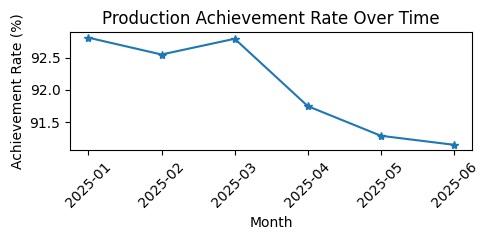

In [9]:
plt.figure(figsize=(5, 2.5))

plt.plot(
    monthly.index.astype(str),
    monthly["achievement_rate"] * 100,
    marker="*"
)

plt.title("Production Achievement Rate Over Time")
plt.xlabel("Month")
plt.ylabel("Achievement Rate (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
## Machine comparison

In [10]:
machine_comparison=(df.groupby("machine").agg
                    (
                        Records=("record_id","count"),
                        Target=("production_target","sum"),
                        Actual=("actual_production", "sum"),
                        Avg_Downtime=("downtime_hours", "mean"),
                        Defects=("defective_units", "sum")
                    )
                   )
machine_comparison["achievement_rate"] = (
    machine_comparison["Actual"] / machine_comparison["Target"]
)
machine_comparison
      

,Records,Target,Actual,Avg_Downtime,Defects,achievement_rate
machine,,,,,,
Kiln A,933,858495,799418,0.739118,17927,0.931185
Kiln B,802,707089,632881,1.330936,18303,0.895051
Mill A,749,492329,457826,0.778222,10292,0.929919
Mill B,716,456727,424993,0.759427,9485,0.930519


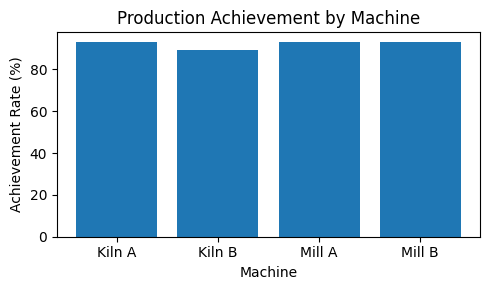

In [11]:
plt.figure(figsize=(5,3))

plt.bar(
    machine_comparison.index,
    machine_comparison["achievement_rate"] * 100
)

plt.title("Production Achievement by Machine")
plt.xlabel("Machine")
plt.ylabel("Achievement Rate (%)")

plt.tight_layout()
plt.show()

In [ ]:
## Shift Comparison

In [12]:
shift_comparison=(df.groupby("shift").agg(
          Records=("record_id", "count"),
          Target=("production_target", "sum"),
          Actual=("actual_production", "sum"),
          Avg_Downtime=("downtime_hours", "mean")
)
                 )

shift_comparison["achievement_rate"] = (
    shift_comparison["Actual"] / shift_comparison["Target"]
)
shift_comparison



,Records,Target,Actual,Avg_Downtime,achievement_rate
shift,,,,,
Afternoon,1205,950735,882246,0.848912,0.927962
Morning,1239,972410,921453,0.841846,0.947597
Night,756,591495,511419,1.081415,0.864621


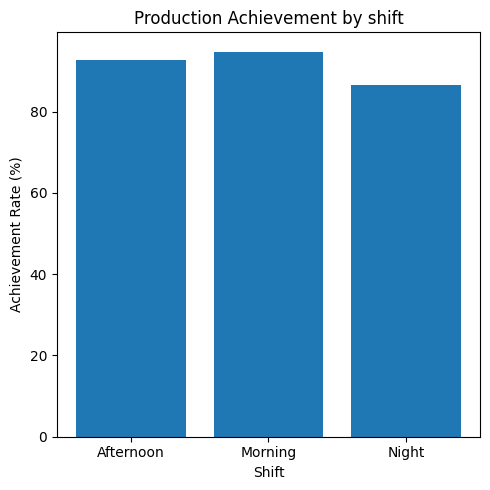

In [13]:
plt.figure(figsize=(5,5))

plt.bar(
    shift_comparison.index,
    shift_comparison["achievement_rate"]*100
)
plt.title("Production Achievement by shift")
plt.xlabel("Shift")
plt.ylabel("Achievement Rate (%)")

plt.tight_layout()
plt.show()

In [ ]:
# Downtime Vs Achievement

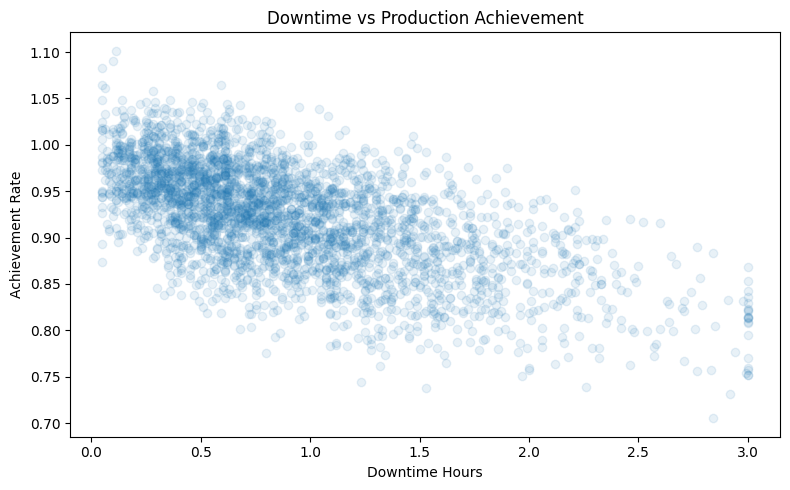

In [14]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["downtime_hours"],
    df["achievement_rate"],
    alpha=0.1
)

plt.title("Downtime vs Production Achievement")
plt.xlabel("Downtime Hours")
plt.ylabel("Achievement Rate")

plt.tight_layout()
plt.show()

In [15]:
correlation = df[["downtime_hours", "achievement_rate"]].corr()

correlation

,downtime_hours,achievement_rate
downtime_hours,1.000000,-0.606096
achievement_rate,-0.606096,1.000000


In [ ]:
## higher downtime is strongly associated with  lower achievement rate.

In [ ]:
# Defects Vs Achievements

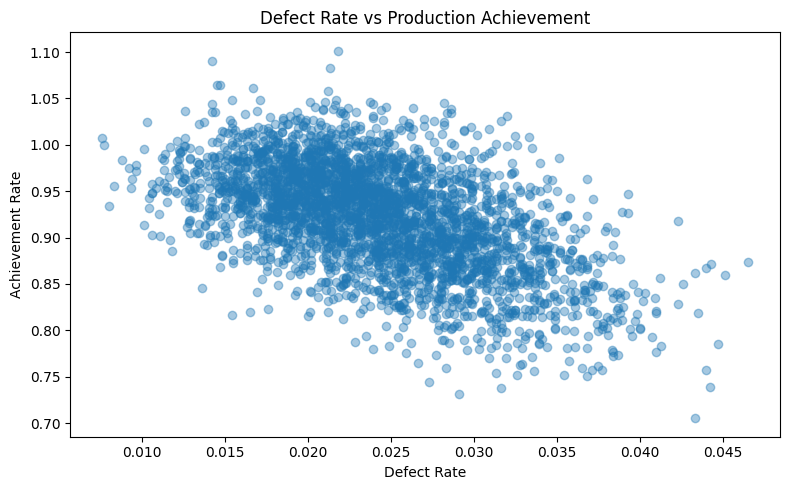

In [16]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["defect_rate"],
    df["achievement_rate"],
    alpha=0.4
)

plt.title("Defect Rate vs Production Achievement")
plt.xlabel("Defect Rate")
plt.ylabel("Achievement Rate")

plt.tight_layout()
plt.show()

In [18]:
df[ ["defect_rate", "achievement_rate"]].corr()

,defect_rate,achievement_rate
defect_rate,1.000000,-0.537957
achievement_rate,-0.537957,1.000000


In [ ]:
#Defect rate is indirectly proportional to achievemnet rate 

In [ ]:
# Distribution Analysis

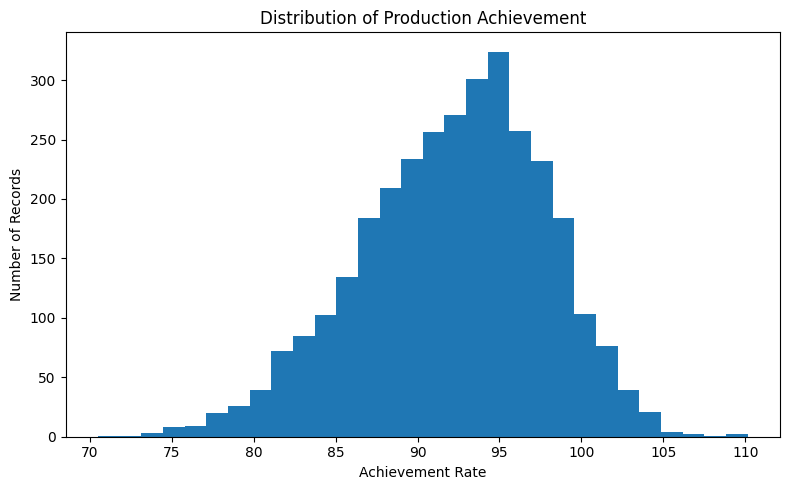

In [22]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["achievement_rate"]*100,
    bins=30
)

plt.title("Distribution of Production Achievement")
plt.xlabel("Achievement Rate")
plt.ylabel("Number of Records")

plt.tight_layout()

plt.show()

In [21]:
df["achievement_rate"].describe()

count    3200.000000
mean        0.921667
std         0.056378
min         0.705100
25%         0.884700
50%         0.926750
75%         0.962225
max         1.101400
Name: achievement_rate, dtype: float64

In [ ]:
# Operations are stable: The majority of records (75%) consistently hit above 88.5% achievement,
# proving daily operations are reliable.

In [ ]:
# Statistical Reasoning


In [24]:
df.groupby("machine")["achievement_rate"].agg(
    ["count", "mean", "median", "std"])

,count,mean,median,std
machine,,,,
Kiln A,933,0.931152,0.93710,0.051826
Kiln B,802,0.895023,0.89680,0.059386
Mill A,749,0.929833,0.93490,0.053114
Mill B,716,0.930610,0.93525,0.052477


In [26]:
df.groupby("shift")["achievement_rate"].agg(
    ["count", "mean", "median", "std"])

,count,mean,median,std
shift,,,,
Afternoon,1205,0.929070,0.93320,0.045569
Morning,1239,0.948654,0.95160,0.047789
Night,756,0.865640,0.86865,0.044558


In [ ]:
## kiln B is clear outlier with mean 89.5% and median 89.6%, it has also highest standard deviation.
## this means Kiln B require maintainance
## Night shift is also struggling with only 86.5% achievement 